In [1]:
from pathlib import Path
import os 

root = Path.cwd().parents[1]
os.chdir(root/"sysml")
from diagramming.diagram import StructuredGraphBuilder

## Concept:

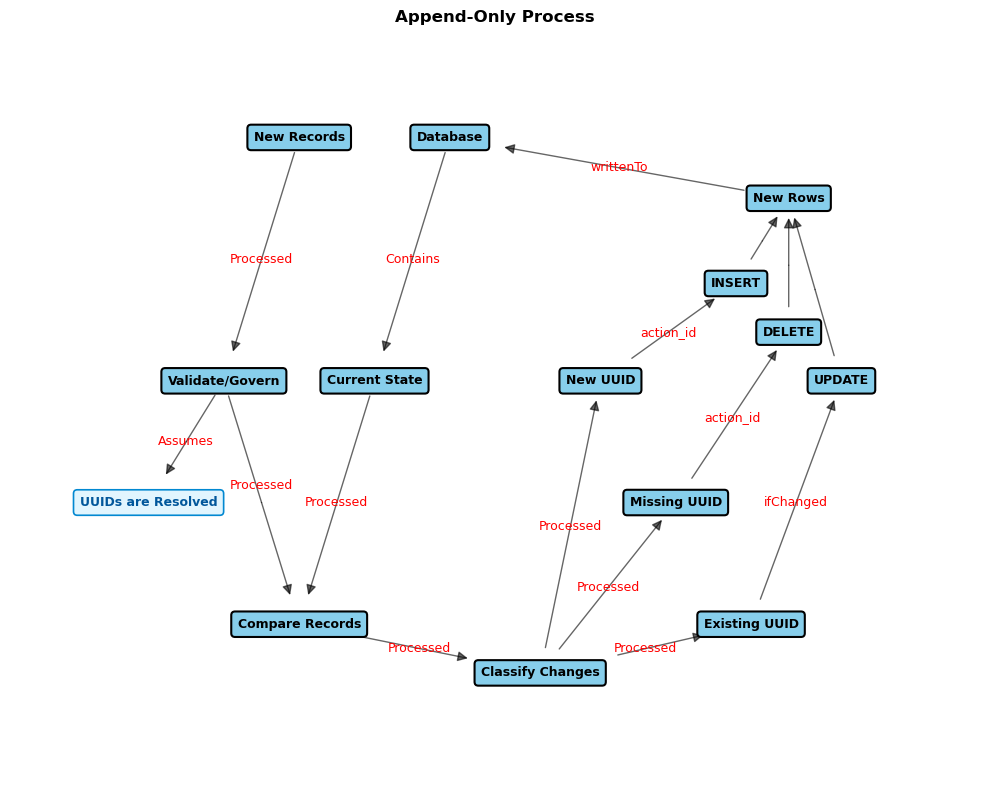

In [2]:
demo = StructuredGraphBuilder()
demo.add_entity("Database", pos=(4, 3))
demo.add_entity("Current State", pos=(3.5, 2))
demo.add_entity("New Records", pos=(3, 3))
demo.add_entity("Validate/Govern", pos=(2.5, 2))
demo.add_entity("Compare Records", pos=(3, 1))
demo.add_entity("Classify Changes", pos=(4.6, 0.8))
uuid_status={"New UUID": "INSERT", "Missing UUID": "DELETE", "Existing UUID": "UPDATE"}
demo.add_entity("New Rows", pos=(6.25, 2.75))
for i, (k, v) in enumerate(uuid_status.items()):
    demo.add_entity(k, pos=(5+i*0.5, 2-0.5*i))
    demo.add_entity(v, pos=(5.9+i*0.35, 2.4-0.2*i))
    demo.add_reified_edge(source="Classify Changes", rel_name="Processed", target=k)
    demo.add_reified_edge(source=k, rel_name="action_id" if k != "Existing UUID" else "ifChanged", target=v)
    demo.add_reified_edge(source=v, rel_name="", target="New Rows")
demo.add_property(target_node_id="Validate/Govern", prop_name="Assumes", prop_value="UUIDs are Resolved", val_pos=(2, 1.5))
    
demo.add_reified_edge(source="New Rows", rel_name="writtenTo", target="Database")
demo.add_reified_edge(source="Database", rel_name="Contains", target="Current State")
demo.add_reified_edge(source="New Records", rel_name="Processed", target="Validate/Govern")
demo.add_reified_edge(source="Current State", rel_name="Processed", target="Compare Records")
demo.add_reified_edge(source="Validate/Govern", rel_name="Processed", target="Compare Records")
demo.add_reified_edge(source="Compare Records", rel_name="Processed", target="Classify Changes")


demo.draw('Append-Only Process', figsize=(10, 8))

## Test Data:

In [3]:
import pandas as pd
import uuid

df = pd.DataFrame({
    "uuid": ["a001", "a002", "a003", "a004", "a005"],
    "name": ["Engine", "Fuel System", "Control System", "Power Supply", "Cooling System",],
    "element_type": ["Block"] * 5,
    "description": [
        "Primary propulsion engine",
        "Provides fuel to the engine",
        "Controls engine operation",
        "Provides electrical power",
        "Provides engine cooling",
    ],
})

df2 = pd.DataFrame({
    "uuid": ["a001", "a002", "a003", "a005", "a006"],
    "name": ["Engine", "Fuel Delivery System", "Control System", "Cooling System", "Exhaust System",],
    "element_type": ["Block"] * 5,
    "description": [
        "Primary propulsion engine and power source",
        "Provides fuel to the engine",
        "Controls engine operation",
        "Provides engine cooling",
        "Routes engine exhaust gases",
    ],
})

### Comparision Function:

In [4]:
def _is_missing(value):
    """Safely identify scalar missing values."""
    result = pd.isna(value)
    return bool(result) if isinstance(result, bool) else False


def _values_equal(a, b):
    """Compare values while treating missing values as equal."""
    if _is_missing(a) and _is_missing(b):
        return True

    if _is_missing(a) or _is_missing(b):
        return False

    result = a == b
    return bool(result) if isinstance(result, bool) else False


def compare_dataframes(df, df2, record_type="element", key="uuid", current_versions=None,):
    """
    Compare current and target DataFrames.
    Returns:
        df_changes
        df_snapshots
        df_deltas
        df_unchanged
    """
    current_versions = current_versions or {}
    # Validate inputs
    if key not in df.columns or key not in df2.columns:
        raise ValueError(f"Both DataFrames must contain '{key}'.")
    if df.columns.duplicated().any() or df2.columns.duplicated().any():
        raise ValueError("Duplicate column names are not supported.")
    if df[key].isna().any() or df2[key].isna().any():
        raise ValueError("Record UUIDs cannot be missing.")
    if df[key].duplicated().any() or df2[key].duplicated().any():
        raise ValueError("Record UUIDs must be unique.")
    if set(df.columns) != set(df2.columns):
        raise ValueError("DataFrame schemas must match.")
    # Identify key and attribute columns
    columns = list(df.columns)
    attributes = [c for c in columns if c != key]
    # Index DataFrames by key
    current = df.set_index(key)
    target = df2.set_index(key)
    # Identify inserted, deleted, and common records
    current_ids = set(current.index)
    target_ids = set(target.index)
    # Calculate record changes
    inserted = target_ids - current_ids
    deleted = current_ids - target_ids
    common = current_ids & target_ids
    # Initialize result containers
    changes = []
    snapshots = []
    deltas = []
    unchanged = []

    def add_change(record_id, change_type, version, old_row, new_row):
        change_uuid = str(uuid.uuid4())
        if change_type == "INSERT":
            snapshot = new_row
            changed_columns = attributes
        elif change_type == "DELETE":
            snapshot = old_row
            changed_columns = []
        else:
            snapshot = new_row
            changed_columns = [col for col in attributes if not _values_equal(old_row[col], new_row[col])]
        changes.append({
            "change_uuid": change_uuid,
            "record_uuid": record_id,
            "record_type": record_type,
            "version": version,
            "change_type": change_type,
            "changed_columns": changed_columns,
        })
        # Full snapshot
        snapshots.append({
            "change_uuid": change_uuid,
            "record_uuid": record_id,
            "record_type": record_type,
            "version": version,
            "change_type": change_type,
            **snapshot.to_dict(),
        })
        # Attribute-level deltas
        for col in attributes:
            old_value = old_row[col] if old_row is not None else None
            new_value = new_row[col] if new_row is not None else None
            if change_type == "INSERT":
                changed = True
            elif change_type == "DELETE":
                changed = True
            else:
                changed = not _values_equal(old_value, new_value)
            if changed:
                deltas.append({
                    "change_uuid": change_uuid,
                    "record_uuid": record_id,
                    "attribute_name": col,
                    "old_value": old_value,
                    "new_value": new_value,
                })
    # Insertions
    for record_id in sorted(inserted):
        version = current_versions.get(record_id, 0) + 1
        add_change(record_id, "INSERT", version, None, target.loc[record_id])
    # Updates and unchanged records
    for record_id in sorted(common):
        old_row = current.loc[record_id]
        new_row = target.loc[record_id]
        changed = any(not _values_equal(old_row[col], new_row[col]) for col in attributes)
        # Version 
        version = current_versions.get(record_id, 1)
        if changed:
            add_change(record_id, "UPDATE", version + 1, old_row, new_row)
        else:
            unchanged.append({"record_uuid": record_id, "status": "UNCHANGED", "version": version,})
    # Deletions
    for record_id in sorted(deleted):
        version = current_versions.get(record_id, 1) + 1
        add_change(record_id, "DELETE", version, current.loc[record_id], None)
    df_changes = pd.DataFrame(changes)
    df_snapshots = pd.DataFrame(snapshots)
    df_deltas = pd.DataFrame(deltas)
    df_unchanged = pd.DataFrame(unchanged)
    return df_changes, df_snapshots, df_deltas, df_unchanged

In [5]:
df_changes, df_snapshots, df_deltas, df_unchanged = (compare_dataframes(df, df2))

In [6]:
print("CHANGES")
display(df_changes)

print("SNAPSHOTS")
display(df_snapshots)

print("DELTAS")
display(df_deltas)

print("UNCHANGED")
display(df_unchanged)

CHANGES


,change_uuid,record_uuid,record_type,version,change_type,changed_columns
0,78a71d64-3b16-4d52-b5c1-0729284025f2,a006,element,1,INSERT,"[name, element_type, description]"
1,94bae2d7-18b4-43f5-b410-d27b585fe8db,a001,element,2,UPDATE,[description]
2,c69cd433-298c-4b78-a2ef-9e213612bb98,a002,element,2,UPDATE,[name]
3,2bc78549-6e40-4dba-83ec-74ec4e39735b,a004,element,2,DELETE,[]


SNAPSHOTS


,change_uuid,record_uuid,record_type,version,change_type,name,element_type,description
0,78a71d64-3b16-4d52-b5c1-0729284025f2,a006,element,1,INSERT,Exhaust System,Block,Routes engine exhaust gases
1,94bae2d7-18b4-43f5-b410-d27b585fe8db,a001,element,2,UPDATE,Engine,Block,Primary propulsion engine and power source
2,c69cd433-298c-4b78-a2ef-9e213612bb98,a002,element,2,UPDATE,Fuel Delivery System,Block,Provides fuel to the engine
3,2bc78549-6e40-4dba-83ec-74ec4e39735b,a004,element,2,DELETE,Power Supply,Block,Provides electrical power


DELTAS


,change_uuid,record_uuid,attribute_name,old_value,new_value
0,78a71d64-3b16-4d52-b5c1-0729284025f2,a006,name,None,Exhaust System
1,78a71d64-3b16-4d52-b5c1-0729284025f2,a006,element_type,None,Block
2,78a71d64-3b16-4d52-b5c1-0729284025f2,a006,description,None,Routes engine exhaust gases
3,94bae2d7-18b4-43f5-b410-d27b585fe8db,a001,description,Primary propulsion engine,Primary propulsion engine and power source
4,c69cd433-298c-4b78-a2ef-9e213612bb98,a002,name,Fuel System,Fuel Delivery System
5,2bc78549-6e40-4dba-83ec-74ec4e39735b,a004,name,Power Supply,None
6,2bc78549-6e40-4dba-83ec-74ec4e39735b,a004,element_type,Block,None
7,2bc78549-6e40-4dba-83ec-74ec4e39735b,a004,description,Provides electrical power,None


UNCHANGED


,record_uuid,status,version
0,a003,UNCHANGED,1
1,a005,UNCHANGED,1


In [7]:
def reconstruct_from_snapshots(df_baseline, df_snapshots, key="uuid"):
    """Reconstruct current state from baseline and full snapshots."""
    state = {row[key]: row.to_dict() for _, row in df_baseline.iterrows()}
    if df_snapshots.empty:
        return df_baseline.copy().reset_index(drop=True)
    latest = (df_snapshots .sort_values(["record_uuid", "version"]) .drop_duplicates("record_uuid", keep="last"))
    for _, change in latest.iterrows():
        record_id = change["record_uuid"]
        if change["change_type"] == "DELETE":
            state.pop(record_id, None)
        else:
            state[record_id] = {col: (record_id if col == key else change[col]) for col in df_baseline.columns}
    return pd.DataFrame(list(state.values()), columns=df_baseline.columns,).reset_index(drop=True)

def reconstruct_from_deltas(df_baseline, df_changes, df_deltas, key="uuid",):
    """Reconstruct current state by replaying attribute deltas."""
    state = {row[key]: row.to_dict() for _, row in df_baseline.iterrows()}
    if df_changes.empty:
        return df_baseline.copy().reset_index(drop=True)
    ordered = df_changes.sort_values(["record_uuid", "version"])
    for _, change in ordered.iterrows():
        record_id = change["record_uuid"]
        change_uuid = change["change_uuid"]
        change_type = change["change_type"]
        record_deltas = df_deltas[df_deltas["change_uuid"] == change_uuid]
        if change_type == "DELETE":
            state.pop(record_id, None)
            continue
        if change_type == "INSERT":
            state[record_id] = {key: record_id}
        if change_type in ("INSERT", "UPDATE"):
            for _, delta in record_deltas.iterrows():
                state[record_id][delta["attribute_name"]] = (delta["new_value"])
    return pd.DataFrame(list(state.values()), columns=df_baseline.columns,).reset_index(drop=True)

df_snapshot_result = reconstruct_from_snapshots(df, df_snapshots)
df_delta_result = reconstruct_from_deltas(df, df_changes, df_deltas)

def normalize(df):
    return (df.sort_values("uuid") .reset_index(drop=True) .sort_index(axis=1))

# Snapshot reconstruction vs delta reconstruction
pd.testing.assert_frame_equal(normalize(df_snapshot_result), normalize(df_delta_result), check_dtype=False,)
# Reconstructed state vs target state
pd.testing.assert_frame_equal(normalize(df_snapshot_result), normalize(df2), check_dtype=False,)
print("Both reconstruction methods passed.")


Both reconstruction methods passed.


## Take 2:

In [8]:
import pandas as pd
import uuid


def _is_missing(value):
    result = pd.isna(value)
    return bool(result) if pd.api.types.is_scalar(result) else False


def _values_equal(a, b):
    if _is_missing(a) and _is_missing(b):
        return True

    if _is_missing(a) or _is_missing(b):
        return False

    result = a == b
    return bool(result) if pd.api.types.is_scalar(result) else False


def initialize_history(df, record_type="element", key="uuid"):
    """Create version-1 INSERT snapshots for the baseline."""

    if key not in df.columns:
        raise ValueError(f"Missing key column: {key}")

    if df[key].isna().any() or df[key].duplicated().any():
        raise ValueError("Record UUIDs must be present and unique.")

    events = []

    for _, row in df.iterrows():
        record_id = row[key]

        events.append({
            "change_uuid": str(uuid.uuid4()),
            "record_uuid": record_id,
            "record_type": record_type,
            "version": 1,
            "change_type": "INSERT",
            "changed_attribute": None,
            **row.to_dict(),
        })

    columns = [
        "change_uuid",
        "record_uuid",
        "record_type",
        "version",
        "change_type",
        "changed_attribute",
        *df.columns,
    ]

    return pd.DataFrame(events, columns=columns)

In [9]:
def append_history_events(df_current, df_incoming, df_history, record_type="element", key="uuid",):
    """Generate full-snapshot events for INSERT, UPDATE, and DELETE."""
    if key not in df_current.columns or key not in df_incoming.columns:
        raise ValueError(f"Both DataFrames must contain '{key}'.")
    if set(df_current.columns) != set(df_incoming.columns):
        raise ValueError("DataFrame schemas must match.")
    for frame in (df_current, df_incoming):
        if frame[key].isna().any() or frame[key].duplicated().any():
            raise ValueError("Record UUIDs must be present and unique.")

    attributes = [col for col in df_current.columns if col != key]

    current = df_current.set_index(key)
    incoming = df_incoming.set_index(key)

    current_ids = set(current.index)
    incoming_ids = set(incoming.index)

    inserted = incoming_ids - current_ids
    deleted = current_ids - incoming_ids
    common = current_ids & incoming_ids

    latest_versions = (
        df_history.groupby("record_uuid")["version"].max().to_dict()
        if not df_history.empty else {}
    )

    events = []
    unchanged = []

    def add_event(record_id, version, change_type, snapshot,
                  changed_attribute=None):

        event = {
            "change_uuid": str(uuid.uuid4()),
            "record_uuid": record_id,
            "record_type": record_type,
            "version": version,
            "change_type": change_type,
            "changed_attribute": changed_attribute,
            key: record_id,
            **snapshot.to_dict(),
        }

        events.append(event)

    # INSERT
    for record_id in sorted(inserted):
        version = latest_versions.get(record_id, 0) + 1

        add_event(
            record_id,
            version,
            "INSERT",
            incoming.loc[record_id],
        )

    # UPDATE
    for record_id in sorted(common):
        old_row = current.loc[record_id]
        new_row = incoming.loc[record_id]

        changed = [col for col in attributes if not _values_equal(old_row[col], new_row[col])]

        if changed:
            version = latest_versions.get(record_id, 1) + 1

            for attribute in changed:
                add_event(record_id, version, "UPDATE", new_row, changed_attribute=attribute,)
        else:
            unchanged.append({
                "record_uuid": record_id,
                "version": latest_versions.get(record_id, 1),
                "status": "UNCHANGED",
            })
    # DELETE
    for record_id in sorted(deleted):
        version = latest_versions.get(record_id, 1) + 1
        add_event(record_id, version, "DELETE", current.loc[record_id],)
    df_events = pd.DataFrame(events, columns=df_history.columns)
    df_updated_history = pd.concat([df_history, df_events], ignore_index=True,)

    return (df_updated_history, df_events, pd.DataFrame(unchanged),)

In [10]:
def reconstruct_from_history(df_history):
    """Reconstruct current state from full-snapshot history."""

    if df_history.empty:
        return pd.DataFrame()

    latest = (
        df_history
        .sort_values(["record_uuid", "version"])
        .drop_duplicates("record_uuid", keep="last")
    )

    current = latest[
        latest["change_type"] != "DELETE"
    ].copy()

    metadata_columns = {
        "change_uuid",
        "record_uuid",
        "record_type",
        "version",
        "change_type",
        "changed_attribute",
    }

    entity_columns = [
        col for col in df_history.columns
        if col not in metadata_columns
    ]

    return current[entity_columns].reset_index(drop=True)

In [11]:
# Step 1: Record the initial baseline.
df_history = initialize_history(df)

# Step 2: Compare the baseline against the incoming model.
df_history, df_events, df_unchanged = append_history_events(df_current=df, df_incoming=df2, df_history=df_history,)

# Step 3: Reconstruct the current state.
df_reconstructed = reconstruct_from_history(df_history)

# Step 4: Validate the reconstruction.
def normalize(df):
    return (df.sort_values("uuid").reset_index(drop=True).sort_index(axis=1))

pd.testing.assert_frame_equal(normalize(df_reconstructed), normalize(df2), check_dtype=False,)

print("History reconstruction passed.")

History reconstruction passed.


In [12]:
df_history

,change_uuid,record_uuid,record_type,version,change_type,changed_attribute,uuid,name,element_type,description
0,818e8128-d363-40e2-b854-7ed57ab4689e,a001,element,1,INSERT,None,a001,Engine,Block,Primary propulsion engine
1,4aa49b1b-4053-4a92-8201-4abc01fec54a,a002,element,1,INSERT,None,a002,Fuel System,Block,Provides fuel to the engine
2,abf9fbff-f4aa-4449-a968-ac5ab5af7a23,a003,element,1,INSERT,None,a003,Control System,Block,Controls engine operation
3,f49ace8c-adc9-49e9-826f-586259dfbeca,a004,element,1,INSERT,None,a004,Power Supply,Block,Provides electrical power
4,1cc0b1ae-524e-463c-bc95-3745df0f0600,a005,element,1,INSERT,None,a005,Cooling System,Block,Provides engine cooling
5,b3329618-cad6-4b02-a324-3e4e90c77b7d,a006,element,1,INSERT,None,a006,Exhaust System,Block,Routes engine exhaust gases
6,9ebd4145-6e74-45b3-b9ab-72be7b7a2477,a001,element,2,UPDATE,description,a001,Engine,Block,Primary propulsion engine and power source
7,3a171852-b6c4-4067-bb08-f10162be067b,a002,element,2,UPDATE,name,a002,Fuel Delivery System,Block,Provides fuel to the engine
8,6c873c14-2b9d-43be-8502-4aa97a552247,a004,element,2,DELETE,None,a004,Power Supply,Block,Provides electrical power


# Schema Inspection:

In [13]:
import pandas as pd
from sqlalchemy import inspect

def sqlalchemy_schema_to_df(base, include_constraints=True,):
    """Convert SQLAlchemy declarative metadata into a DataFrame."""
    metadata = base.metadata
    rows = []
    for table in metadata.sorted_tables:
        # Identify foreign keys by column.
        foreign_keys = {fk.parent.name: (f"{fk.target_fullname}") for fk in table.foreign_keys}
        # Identify columns belonging to unique constraints.
        unique_columns = set()
        for constraint in table.constraints:
            if constraint.__class__.__name__ == "UniqueConstraint":
                unique_columns.update(column.name for column in constraint.columns)
        # Identify indexed columns.
        indexed_columns = set()
        for index in table.indexes:
            indexed_columns.update(column.name for column in index.columns)
        for column in table.columns:
            rows.append({
                "schema": table.schema,
                "table": table.name,
                "column": column.name,
                "type": str(column.type),
                "nullable": column.nullable,
                "primary_key": column.primary_key,
                "foreign_key": foreign_keys.get(column.name),
                "unique": column.name in unique_columns,
                "indexed": column.name in indexed_columns,
                "default": (str(column.default.arg) if column.default is not None else None),
                "server_default": str(column.server_default.arg) if column.server_default is not None else None
            })
    return pd.DataFrame(rows)



In [17]:
os.chdir("C:/Users/Drew/Documents/MyFiles/repo/database/prod/backend")
from app.database import MBSE
import app.models.mbse

df_schema = sqlalchemy_schema_to_df(MBSE)
print(df_schema.to_string(index=False))

schema                            table                       column      type  nullable  primary_key                  foreign_key  unique  indexed                                                    default    server_default
  mbse                engineering_model                         name      TEXT     False        False                         None    True    False                                                       None              None
  mbse                engineering_model                  description      TEXT      True        False                         None   False    False                                                       None              None
  mbse                engineering_model                  source_tool      TEXT      True        False                         None   False    False                                                       None              None
  mbse                engineering_model                source_format      TEXT      True        Fals

In [20]:
from app.database import MBSE
import app.models.mbse

for table_name, table in MBSE.metadata.tables.items():
    print(
        f"Key: {table_name:<40} "
        f"Name: {table.name:<30} "
        f"Schema: {table.schema}"
    )

Key: mbse.engineering_model                   Name: engineering_model              Schema: mbse
Key: mbse.model_version                       Name: model_version                  Schema: mbse
Key: mbse.object_definition                   Name: object_definition              Schema: mbse
Key: mbse.relationship_definition             Name: relationship_definition        Schema: mbse
Key: mbse.instance_definition                 Name: instance_definition            Schema: mbse
Key: mbse.class_taxonomy                      Name: class_taxonomy                 Schema: mbse
Key: mbse.object_relationships                Name: object_relationships           Schema: mbse
Key: mbse.relationship_endpoints              Name: relationship_endpoints         Schema: mbse
Key: mbse.stereotypes                         Name: stereotypes                    Schema: mbse
Key: mbse.applied_stereotypes                 Name: applied_stereotypes            Schema: mbse
Key: mbse.object_instance_properties    

In [21]:
for table in MBSE.metadata.tables.values():
    print(table.fullname, table.schema)

mbse.engineering_model mbse
mbse.model_version mbse
mbse.object_definition mbse
mbse.relationship_definition mbse
mbse.instance_definition mbse
mbse.class_taxonomy mbse
mbse.object_relationships mbse
mbse.relationship_endpoints mbse
mbse.stereotypes mbse
mbse.applied_stereotypes mbse
mbse.object_instance_properties mbse
mbse.relationship_instance_properties mbse
